# Modelo de Fama-French de 3 factores en ETFs sectoriales
**MA2003B — Aplicación de métodos multivariados en ciencia de datos**  
Prof. Dr. Jonathan Montalvo Urquizo · Octubre 2026

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import requests
import zipfile
import io
import math

USE_FAMAFRENCH_3 = True
tickers = ["XLK", "XLF", "XLV", "XLE"]
fecha_inicio = "1990-01-01"
fecha_fin = "2026-10-01"

In [56]:
datos_diarios = yf.download(tickers, start=fecha_inicio, end=fecha_fin,
                            auto_adjust=True, progress=False)
precios_diarios = datos_diarios["Close"]
precios_mensuales = precios_diarios.resample("ME").last()
rendimientos = (precios_mensuales / precios_mensuales.shift(1)) - 1
rendimientos = rendimientos.dropna()
print(rendimientos.head())
print("Dimensiones rendimientos:", rendimientos.shape)

Ticker           XLE       XLF       XLK       XLV
Date                                              
1999-01-31 -0.065596  0.017333  0.159004  0.048078
1999-02-28 -0.008596  0.015728 -0.099174  0.001147
1999-03-31  0.141372  0.032410  0.074312  0.026346
1999-04-30  0.148031  0.070176  0.005977  0.035714
1999-05-31 -0.021583 -0.060305  0.003396 -0.030712
Dimensiones rendimientos: (333, 4)


In [57]:
URL_FF = ("https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/"
          "F-F_Research_Data_Factors_CSV.zip")

resp = requests.get(URL_FF)
resp.raise_for_status()
z = zipfile.ZipFile(io.BytesIO(resp.content))
nombre_csv = z.namelist()[0]
with z.open(nombre_csv) as f:
    texto = f.read().decode("latin-1")
lineas = texto.splitlines()

# 1) Detectar cabecera: la línea cuyos campos (tras split por coma y strip)
#    contienen exactamente Mkt-RF, SMB, HML y RF. Tolera coma inicial vacía,
#    comillas, espacios y mayúsculas/minúsculas.
def es_cabecera(ln):
    campos = [c.strip().strip('"').strip() for c in ln.split(",")]
    campos_norm = [c.upper().replace(" ", "").replace("_", "-") for c in campos]
    return all(f in campos_norm for f in ["MKT-RF", "SMB", "HML", "RF"])

inicio_datos = None
for i, ln in enumerate(lineas):
    if es_cabecera(ln):
        inicio_datos = i + 1
        break

if inicio_datos is None:
    print("No se encontró la cabecera. Primeras 40 líneas:")
    for ln in lineas[:40]:
        print(repr(ln))
    raise ValueError("Cabecera de factores no encontrada.")

print(f"Cabecera encontrada en línea {inicio_datos - 1}: {lineas[inicio_datos - 1]!r}")

# 2) Leer SOLO el bloque mensual: filas cuyo primer campo sea YYYYMM (6 dígitos).
#    Se corta en la primera línea vacía o cuando el primer campo deje de ser 6 dígitos
#    (eso marca el inicio del bloque anual u otra sección).
filas = []
for ln in lineas[inicio_datos:]:
    if ln.strip() == "":
        break
    campos = [c.strip().strip('"').strip() for c in ln.split(",")]
    # Quitar posibles campos vacíos al inicio (por la coma desplazada del header)
    while campos and campos[0] == "":
        campos.pop(0)
    if len(campos) < 5:
        break
    primer = campos[0]
    if not (primer.isdigit() and len(primer) == 6):
        break
    filas.append(campos[:5])

if not filas:
    print("Bloque mensual vacío. Líneas posteriores a la cabecera:")
    for ln in lineas[inicio_datos:inicio_datos+10]:
        print(repr(ln))
    raise ValueError("No se leyeron filas mensuales del CSV de FF.")

# 3) Construir DataFrame y limpiar
factores = pd.DataFrame(filas, columns=["YYYYMM", "Mkt-RF", "SMB", "HML", "RF"])
factores["YYYYMM"] = factores["YYYYMM"].astype(str).str.strip()
factores = factores[factores["YYYYMM"].str.fullmatch(r"\d{6}")].copy()

factores["Fecha"] = pd.to_datetime(factores["YYYYMM"], format="%Y%m", errors="coerce")
factores = factores.dropna(subset=["Fecha"]).set_index("Fecha")

columnas_deseadas = ["Mkt-RF", "SMB", "HML", "RF"]
factores = factores[columnas_deseadas]

factores = factores.apply(pd.to_numeric, errors="coerce") / 100.0
factores = factores.dropna()

if USE_FAMAFRENCH_3:
    factores = factores[["Mkt-RF", "SMB", "HML", "RF"]]

print("Primeras filas factores:")
print(factores.head())
print("Dimensiones factores:", factores.shape)
print("Rango de fechas:", factores.index.min(), "a", factores.index.max())

Cabecera encontrada en línea 4: ',Mkt-RF,SMB,HML,RF'
Primeras filas factores:
            Mkt-RF     SMB     HML      RF
Fecha                                     
1926-07-01  0.0289 -0.0242 -0.0275  0.0022
1926-08-01  0.0264 -0.0144  0.0413  0.0025
1926-09-01  0.0038 -0.0136  0.0005  0.0023
1926-10-01 -0.0327 -0.0018  0.0078  0.0032
1926-11-01  0.0254 -0.0017 -0.0048  0.0031
Dimensiones factores: (1202, 4)
Rango de fechas: 1926-07-01 00:00:00 a 2026-08-01 00:00:00


In [58]:
# Diagnóstico del join por Period("M")
print("rendimientos.index[:3]:", list(rendimientos.index[:3]))
print("rendimientos.index[-3:]:", list(rendimientos.index[-3:]))

rend_p = rendimientos.copy()
rend_p.index = rend_p.index.to_period("M")
print("Period rendimientos[:3]:", list(rend_p.index[:3]))

fac_p = factores.copy()
fac_p.index = fac_p.index.to_period("M")
print("Period factores[:3]:", list(fac_p.index[:3]))

inter = rend_p.index.intersection(fac_p.index)
print("Meses comunes:", len(inter))
print("Primer mes común:", inter.min() if len(inter) else "VACÍO")
print("Último mes común:", inter.max() if len(inter) else "VACÍO")

rendimientos.index[:3]: [Timestamp('1999-01-31 00:00:00'), Timestamp('1999-02-28 00:00:00'), Timestamp('1999-03-31 00:00:00')]
rendimientos.index[-3:]: [Timestamp('2026-07-31 00:00:00'), Timestamp('2026-08-31 00:00:00'), Timestamp('2026-09-30 00:00:00')]
Period rendimientos[:3]: [Period('1999-01', 'M'), Period('1999-02', 'M'), Period('1999-03', 'M')]
Period factores[:3]: [Period('1926-07', 'M'), Period('1926-08', 'M'), Period('1926-09', 'M')]
Meses comunes: 332
Primer mes común: 1999-01
Último mes común: 2026-08


In [59]:
rendimientos.index = rendimientos.index.to_period("M")
factores.index = factores.index.to_period("M")

datos = rendimientos.join(factores, how="inner").dropna()

for t in tickers:
    datos[f"{t}_exceso"] = datos[t] - datos["RF"]

print("Primeras filas combinadas:")
print(datos.head())
print("Dimensiones finales:", datos.shape)
print("Periodo comun:", datos.index.min(), "a", datos.index.max())

Primeras filas combinadas:
              XLE       XLF       XLK       XLV  Mkt-RF     SMB     HML      RF  XLK_exceso  XLF_exceso  XLV_exceso  XLE_exceso
Date                                                                                                                           
1999-01 -0.065596  0.017333  0.159004  0.048078  0.0348  0.0066 -0.0442  0.0035    0.155504    0.013833    0.044578   -0.069096
1999-02 -0.008596  0.015728 -0.099174  0.001147 -0.0408 -0.0599  0.0189  0.0035   -0.102674    0.012228   -0.002353   -0.012096
1999-03  0.141372  0.032410  0.074312  0.026346  0.0348 -0.0387 -0.0256  0.0043    0.070012    0.028110    0.022046    0.137072
1999-04  0.148031  0.070176  0.005977  0.035714  0.0434  0.0388  0.0238  0.0037    0.002277    0.066476    0.032014    0.144331
1999-05 -0.021583 -0.060305  0.003396 -0.030712 -0.0246  0.0334  0.0250  0.0034   -0.000004   -0.063705   -0.034112   -0.024983
Dimensiones finales: (332, 12)
Periodo comun: 1999-01 a 2026-08


In [60]:
def _betacf(a, b, x, max_iter=200, eps=3e-14):
    """Fracción continua para la función beta incompleta (Lentz)."""
    qab, qap, qam = a + b, a + 1.0, a - 1.0
    c = 1.0
    d = 1.0 - qab * x / qap
    if abs(d) < 1e-30:
        d = 1e-30
    d = 1.0 / d
    h = d
    for m in range(1, max_iter + 1):
        m2 = 2 * m
        aa = m * (b - m) * x / ((qam + m2) * (a + m2))
        d = 1.0 + aa * d
        if abs(d) < 1e-30:
            d = 1e-30
        c = 1.0 + aa / c
        if abs(c) < 1e-30:
            c = 1e-30
        d = 1.0 / d
        h *= d * c
        aa = -(a + m) * (qab + m) * x / ((a + m2) * (qap + m2))
        d = 1.0 + aa * d
        if abs(d) < 1e-30:
            d = 1e-30
        c = 1.0 + aa / c
        if abs(c) < 1e-30:
            c = 1e-30
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1.0) < eps:
            break
    return h


def _betai(a, b, x):
    """Función beta incompleta regularizada I_x(a,b)."""
    if x <= 0.0:
        return 0.0
    if x >= 1.0:
        return 1.0
    lbeta = math.lgamma(a + b) - math.lgamma(a) - math.lgamma(b)
    bt = math.exp(lbeta + a * math.log(x) + b * math.log(1.0 - x))
    if x < (a + 1.0) / (a + b + 2.0):
        return bt * _betacf(a, b, x) / a
    return 1.0 - bt * _betacf(b, a, 1.0 - x) / b


def t_cdf(t, df):
    """CDF de la t de Student."""
    x = df / (df + t * t)
    p = 0.5 * _betai(df / 2.0, 0.5, x)
    return 1.0 - p if t > 0 else p


def t_pvalue_dos_colas(t, df):
    """p-value bilateral."""
    return 2.0 * (1.0 - t_cdf(abs(t), df))

In [61]:
def ols_qr(X, y):
    """
    Estima y = X theta + eps por MCO usando factorización QR.
    Devuelve theta, residuos, R2, SE, t-stats y p-values.
    Compatible con NumPy 2.x (evita float() sobre arrays (1,1)).
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float).reshape(-1, 1)
    n, k = X.shape

    if n == 0:
        raise ValueError("X tiene 0 filas: revisa que 'datos' no esté vacío.")
    if n < k:
        raise ValueError(f"X tiene {n} filas y {k} columnas: no hay suficientes observaciones.")

    Q, R = np.linalg.qr(X, mode="reduced")

    if R.shape[0] == R.shape[1] and np.all(np.abs(np.diag(R)) > 1e-10):
        theta = np.linalg.solve(R, Q.T @ y)
        I_k = np.eye(k)
        R_inv = np.linalg.solve(R, I_k)
        XtX_inv = R_inv @ R_inv.T
    else:
        # Respaldo robusto: rango deficiente o R no cuadrada
        theta, *_ = np.linalg.lstsq(X, y, rcond=None)
        XtX = X.T @ X
        U, S, Vt = np.linalg.svd(XtX)
        S_inv = np.array([1.0 / s if s > 1e-10 else 0.0 for s in S])
        XtX_inv = (Vt.T * S_inv) @ U.T

    y_hat = X @ theta
    resid = y - y_hat

    # --- CORRECCIÓN NumPy 2.x: extraer escalar con [0, 0] ---
    ss_res = float((resid.T @ resid)[0, 0])
    ss_tot = float(((y - y.mean()) ** 2).sum())
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else float("nan")

    gl = n - k
    if gl <= 0:
        raise ValueError(f"Grados de libertad no positivos: n={n}, k={k}.")
    sigma2 = ss_res / gl

    se = np.sqrt(np.diag(sigma2 * XtX_inv)).reshape(-1, 1)
    se[se == 0] = np.nan
    t_stats = theta / se
    p_values = np.array([
        t_pvalue_dos_colas(float(t_stats[i, 0]), gl)
        if not np.isnan(t_stats[i, 0]) else np.nan
        for i in range(k)
    ]).reshape(-1, 1)

    return {
        "theta": theta,
        "se": se,
        "t": t_stats,
        "p": p_values,
        "resid": resid,
        "y_hat": y_hat,
        "y": y,
        "R2": r2,
        "n": n,
        "k": k,
    }

In [62]:
# --- Verificaciones de sanidad ---
print("datos.shape:", datos.shape)
assert len(datos) > 10, f"datos tiene solo {len(datos)} filas: revisa descarga y join."
for c in ["Mkt-RF", "SMB", "HML"]:
    assert datos[c].std() > 1e-6, f"El factor {c} está constante."

# --- Matriz X común (intercepto + 3 factores) ---
X = np.column_stack([
    np.ones(len(datos)),
    datos["Mkt-RF"].values.astype(float),
    datos["SMB"].values.astype(float),
    datos["HML"].values.astype(float),
])
print("X.shape:", X.shape, "| n filas datos:", len(datos))

nombres_coef = ["alpha", "beta_M", "s_SMB", "h_HML"]

# --- Ajustar los 4 ETFs ---
resultados = {}
for t in tickers:
    y = datos[f"{t}_exceso"].values.astype(float)
    resultados[t] = ols_qr(X, y)

# --- Tabla resumen ---
filas_tabla = []
for t in tickers:
    r = resultados[t]
    fila = {"ETF": t, "R2": round(r["R2"], 4), "n": r["n"]}
    for j, nombre in enumerate(nombres_coef):
        fila[nombre]             = round(float(r["theta"][j, 0]), 4)
        fila[f"SE_{nombre}"]     = round(float(r["se"][j, 0]), 4)
        fila[f"t_{nombre}"]      = round(float(r["t"][j, 0]), 3)
        fila[f"p_{nombre}"]      = round(float(r["p"][j, 0]), 4)
    filas_tabla.append(fila)

tabla = pd.DataFrame(filas_tabla).set_index("ETF")
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
print(tabla)

datos.shape: (332, 12)
X.shape: (332, 4) | n filas datos: 332
         R2    n   alpha  SE_alpha  t_alpha  p_alpha  beta_M  SE_beta_M  t_beta_M  p_beta_M   s_SMB  SE_s_SMB  t_s_SMB  p_s_SMB   h_HML  SE_h_HML  t_h_HML  p_h_HML
ETF                                                                                                                                                                
XLK  0.8339  332  0.0014    0.0015    0.907   0.3650  1.2605     0.0346    36.444       0.0 -0.0669    0.0492   -1.358   0.1754 -0.5948    0.0442  -13.445   0.0000
XLF  0.8394  332 -0.0031    0.0013   -2.331   0.0203  1.1452     0.0307    37.364       0.0 -0.2238    0.0436   -5.131   0.0000  0.7387    0.0392   18.842   0.0000
XLV  0.5666  332  0.0016    0.0015    1.092   0.2756  0.7081     0.0343    20.642       0.0 -0.1880    0.0488   -3.851   0.0001 -0.0021    0.0439   -0.047   0.9624
XLE  0.4638  332  0.0008    0.0030    0.272   0.7858  0.9473     0.0670    14.130       0.0  0.0660    0.0954    0.692

In [63]:
excesos = datos[[f"{t}_exceso" for t in tickers]].copy()
excesos.columns = tickers
matriz_corr = excesos.corr()
print("Matriz de correlaciones de rendimientos excedentes:")
print(matriz_corr.round(4))

Matriz de correlaciones de rendimientos excedentes:
        XLK     XLF     XLV     XLE
XLK  1.0000  0.5177  0.5628  0.3318
XLF  0.5177  1.0000  0.6192  0.5326
XLV  0.5628  0.6192  1.0000  0.4030
XLE  0.3318  0.5326  0.4030  1.0000


In [64]:
def durbin_watson(resid):
    """DW = sum (e_t - e_{t-1})^2 / sum e_t^2."""
    e = resid.ravel()
    return float(((np.diff(e)) ** 2).sum() / (e ** 2).sum())


def breusch_pagan(resid, X):
    """
    BP auxiliar: regresa residuos^2 sobre X (sin constantes extra),
    devuelve el estadístico n*R2 y su p-value chi2 con k-1 gl.
    Implementamos CDF chi2 con la beta incompleta.
    """
    e2 = (resid.ravel() ** 2).reshape(-1, 1)
    aux = ols_qr(X, e2)                # usamos el mismo OLS
    lm = aux["n"] * aux["R2"]
    gl = X.shape[1] - 1
    # CDF chi2(k) = I_{x/2}(k/2, 1/2) ... implementacion via gamma incompleta
    # Usamos la relacion chi2(k) = Gamma(k/2, 2); aproximacion via serie:
    p = _chi2_sf(lm, gl)
    return lm, gl, p


def _gammainc_upper(s, x):
    """Gamma incompleta superior regularizada Q(s,x) (Lentz)."""
    if x < s + 1.0:
        # serie para P(s,x)
        term = 1.0 / s
        suma = term
        n = 1
        while abs(term) > 1e-14 * abs(suma) and n < 500:
            term *= x / (s + n)
            suma += term
            n += 1
        P = suma * math.exp(-x + s * math.log(x) - math.lgamma(s))
        return 1.0 - P
    else:
        # fraccion continua para Q(s,x)
        b = x + 1.0 - s
        c = 1.0 / 1e-30
        d = 1.0 / b
        h = d
        for i in range(1, 500):
            an = -i * (i - s)
            b += 2.0
            d = an * d + b
            if abs(d) < 1e-30:
                d = 1e-30
            c = b + an / c
            if abs(c) < 1e-30:
                c = 1e-30
            d = 1.0 / d
            delta = d * c
            h *= delta
            if abs(delta - 1.0) < 1e-14:
                break
        return h * math.exp(-x + s * math.log(x) - math.lgamma(s))


def _chi2_sf(x, gl):
    """P(chi2_gl > x)"""
    return _gammainc_upper(gl / 2.0, x / 2.0)


for t in tickers:
    r = resultados[t]
    dw = durbin_watson(r["resid"])
    lm, gl, p_bp = breusch_pagan(r["resid"], X)
    e = r["resid"].ravel()
    z = (e - e.mean()) / e.std(ddof=1)
    n_out = int((np.abs(z) > 3).sum())
    print(f"{t}: DW={dw:.3f} | BP LM={lm:.3f} (gl={gl}, p={p_bp:.4f}) "
          f"| outliers(|z|>3)={n_out}")

XLK: DW=2.195 | BP LM=2.811 (gl=3, p=0.4217) | outliers(|z|>3)=5
XLF: DW=2.011 | BP LM=0.735 (gl=3, p=0.8650) | outliers(|z|>3)=4
XLV: DW=1.909 | BP LM=0.256 (gl=3, p=0.9680) | outliers(|z|>3)=3
XLE: DW=2.048 | BP LM=3.745 (gl=3, p=0.2903) | outliers(|z|>3)=2


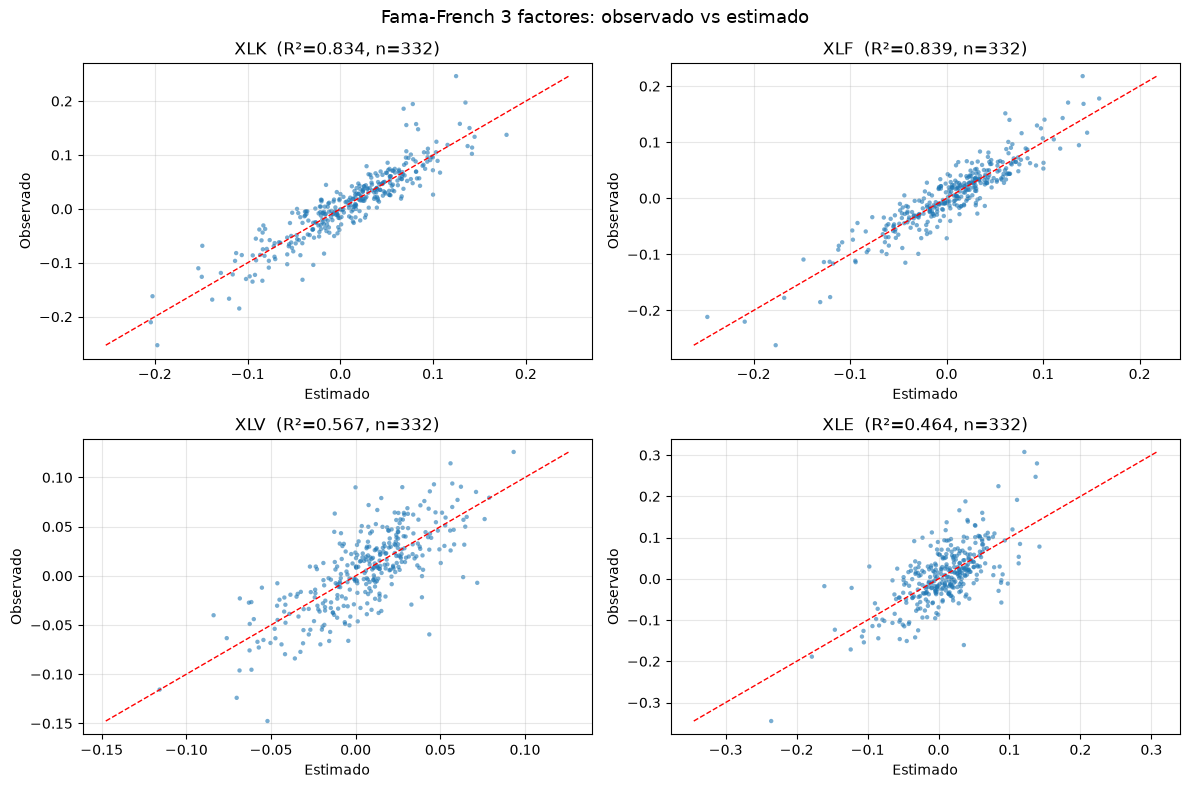

In [65]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, t in zip(axes.ravel(), tickers):
    r = resultados[t]
    y_obs = r["y"].ravel()
    y_hat = r["y_hat"].ravel()
    ax.scatter(y_hat, y_obs, s=10, alpha=0.6, edgecolors="none")
    lims = [min(y_hat.min(), y_obs.min()), max(y_hat.max(), y_obs.max())]
    ax.plot(lims, lims, "r--", lw=1)
    ax.set_title(f"{t}  (R²={r['R2']:.3f}, n={r['n']})")
    ax.set_xlabel("Estimado"); ax.set_ylabel("Observado"); ax.grid(alpha=0.3)
plt.suptitle("Fama-French 3 factores: observado vs estimado", fontsize=13)
plt.tight_layout(); plt.show()

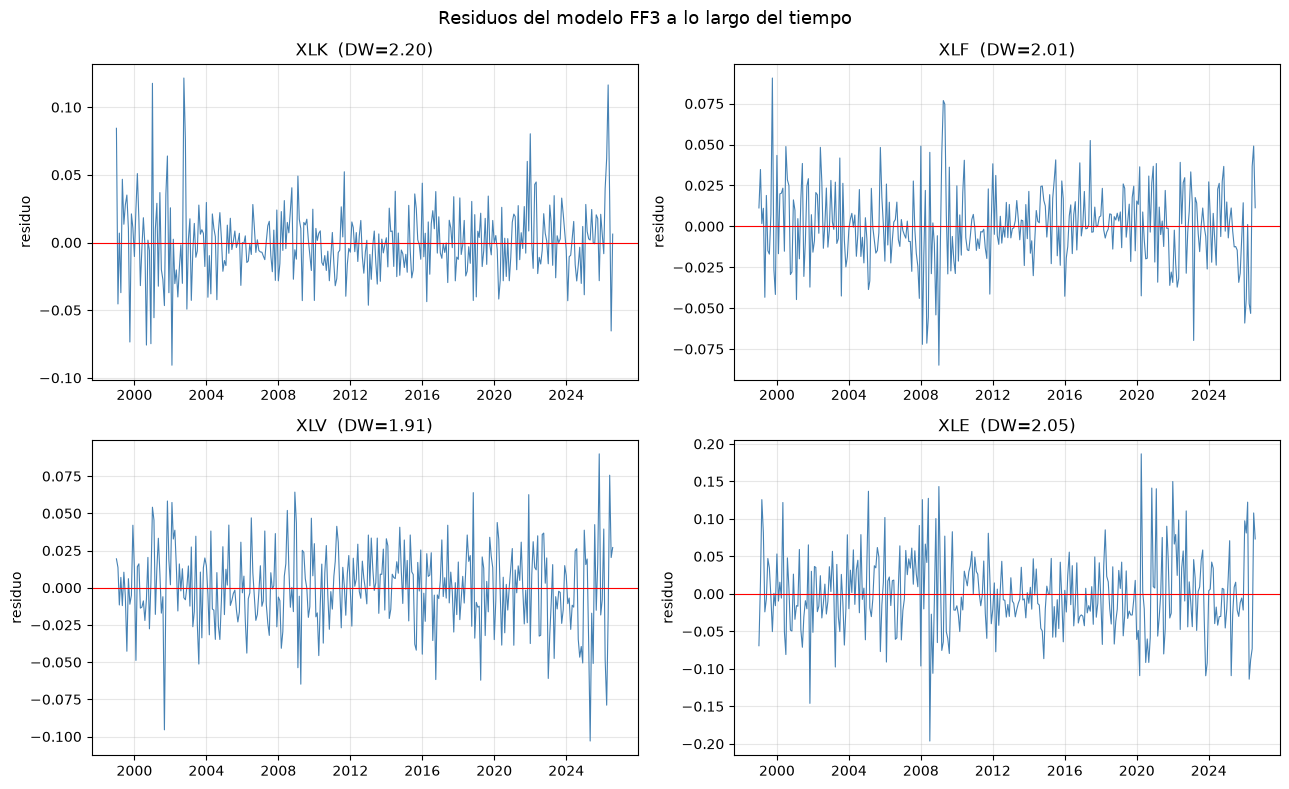

In [66]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
fechas = datos.index.to_timestamp()
for ax, t in zip(axes.ravel(), tickers):
    e = resultados[t]["resid"].ravel()
    ax.plot(fechas, e, lw=0.8, color="steelblue")
    ax.axhline(0, color="red", lw=0.8)
    ax.set_title(f"{t}  (DW={durbin_watson(resultados[t]['resid']):.2f})")
    ax.set_ylabel("residuo"); ax.grid(alpha=0.3)
plt.suptitle("Residuos del modelo FF3 a lo largo del tiempo", fontsize=13)
plt.tight_layout(); plt.show()

In [67]:
tabla.to_csv("tabla_coeficientes_ff3.csv")

def tabla_a_latex(df, decimales=3):
    cols = list(df.columns)
    out = [r"\begin{tabular}{l" + "r" * len(cols) + "}", r"\hline",
           "ETF & " + " & ".join(cols) + r" \\", r"\hline"]
    for idx, fila in df.iterrows():
        vals = [f"{fila[c]:.{decimales}f}"
                if isinstance(fila[c], (int, float, np.floating)) else str(fila[c])
                for c in cols]
        out.append(f"{idx} & " + " & ".join(vals) + r" \\")
    out += [r"\hline", r"\end{tabular}"]
    return "\n".join(out)

print(tabla_a_latex(tabla[["R2", "alpha", "beta_M", "s_SMB", "h_HML"]]))

\begin{tabular}{lrrrrr}
\hline
ETF & R2 & alpha & beta_M & s_SMB & h_HML \\
\hline
XLK & 0.834 & 0.001 & 1.260 & -0.067 & -0.595 \\
XLF & 0.839 & -0.003 & 1.145 & -0.224 & 0.739 \\
XLV & 0.567 & 0.002 & 0.708 & -0.188 & -0.002 \\
XLE & 0.464 & 0.001 & 0.947 & 0.066 & 0.773 \\
\hline
\end{tabular}
